# Exploratory Data Analysis of EM-DAT Dataset

*   Location: Europe
*   Timeframe: 2000-2025
*   Type: Metereological



In [4]:
# Mount drive
#from google.colab import drive
#drive.mount('/content/drive')

In [5]:
import pandas as pd

# Directly load the EM-DAT excel file from Google Drive
file_path = "../data/data_emdat_2000_2025_world.xlsx"
##file_path = '/content/drive/MyDrive/Open Data/EMDAT/data_emdat_2000_2025_world.xlsx'
df = pd.read_excel(file_path)
display(df.head())

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,2025-0303-ECU,No,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,NaN,NaN,ECU,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-04-28,2026-05-15
1,2025-0750-AFG,No,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,GLIDE:EQ-2025-000153,NaN,AFG,...,NaN,NaN,NaN,180000.0,180000.0,100.0,NaN,NaN,2025-09-01,2026-05-15
2,2024-0962-AGO,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000013,Cholera,AGO,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-01-17,2026-05-15
3,2025-9122-SOM,No,nat-cli-dro-dro,Natural,Climatological,Drought,Drought,NaN,NaN,SOM,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-02-26,2026-05-15
4,2025-0272-KGZ,No,nat-bio-epi-vir,Natural,Biological,Epidemic,Viral disease,GLIDE:EP-2025-000030|GLIDE:EP-2025-000105,Measles & Rubella,KGZ,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-04-16,2026-05-20


In [6]:
# Detailed DataFrame summary
print("--- Info Summary ---")
df.info()

--- Info Summary ---
<class 'pandas.DataFrame'>
RangeIndex: 10746 entries, 0 to 10745
Data columns (total 47 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   DisNo.                                     10746 non-null  str    
 1   Historic                                   10746 non-null  str    
 2   Classification Key                         10746 non-null  str    
 3   Disaster Group                             10746 non-null  str    
 4   Disaster Subgroup                          10746 non-null  str    
 5   Disaster Type                              10746 non-null  str    
 6   Disaster Subtype                           10746 non-null  str    
 7   External IDs                               4280 non-null   str    
 8   Event Name                                 2675 non-null   str    
 9   ISO                                        10746 non-null  str    
 10  Country     

In [7]:
# Filter for natural climatological disasters in Europe
df_met_eu = df[
    (df['Disaster Group'] == 'Natural') &
    (df['Disaster Subgroup'] == 'Meteorological') &
    (df['Region'] == 'Europe')
]

# Display the filtered dataframe
display(df_met_eu.head())
print(f"Total disasters found: {len(df_met_eu)}")

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
15,2022-0465-LIE,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,GLIDE:HT-2022-000399,NaN,LIE,...,NaN,NaN,NaN,NaN,NaN,90.902697,NaN,NaN,2026-08-11,2026-08-11
66,2000-0576-RUS,No,nat-met-sto-tro,Natural,Meteorological,Storm,Tropical cyclone,NaN,Typhoon 'Saomai' (Osang),RUS,...,NaN,NaN,NaN,50.0,93.0,53.487737,"[{""adm1_code"":2516,""adm1_name"":""Khabarovskiy K...","[{""gid_1"":""RUS.28_1"",""migration_date"":""2025-12...",2007-04-18,2026-08-20
71,2000-0714-DEU,No,nat-met-sto-sev,Natural,Meteorological,Storm,Severe weather,HANZE:20231|HANZE:21263,Storm 'Oratia' (Tora),DEU,...,NaN,NaN,NaN,NaN,NaN,53.487737,NaN,NaN,2026-08-19,2026-08-19
72,2000-0714-FRA,No,nat-met-sto-sev,Natural,Meteorological,Storm,Severe weather,HANZE:20231|HANZE:21263,Storm 'Oratia' (Tora),FRA,...,NaN,NaN,NaN,NaN,NaN,53.487737,NaN,NaN,2026-08-19,2026-08-19
73,2000-0714-GBR,No,nat-met-sto-sev,Natural,Meteorological,Storm,Severe weather,HANZE:20231|HANZE:21263,Storm 'Oratia' (Tora),GBR,...,NaN,1100000.0,2056546.0,1500000.0,2804381.0,53.487737,"[{""adm2_code"":40107,""adm2_name"":""East Sussex""}...","[{""gid_2"":""GBR.1.105_1"",""migration_date"":""2025...",2008-04-08,2026-08-19


Total disasters found: 732


In [8]:
# Calculate the count of disasters per year
disasters_per_year = df_met_eu.groupby('Start Year').size().reset_index(name='Climate Count')
display(disasters_per_year)

,Start Year,Climate Count
0,2000,25
1,2001,14
2,2002,25
3,2003,22
4,2004,17
5,2005,45
6,2006,25
7,2007,35
8,2008,14
9,2009,27


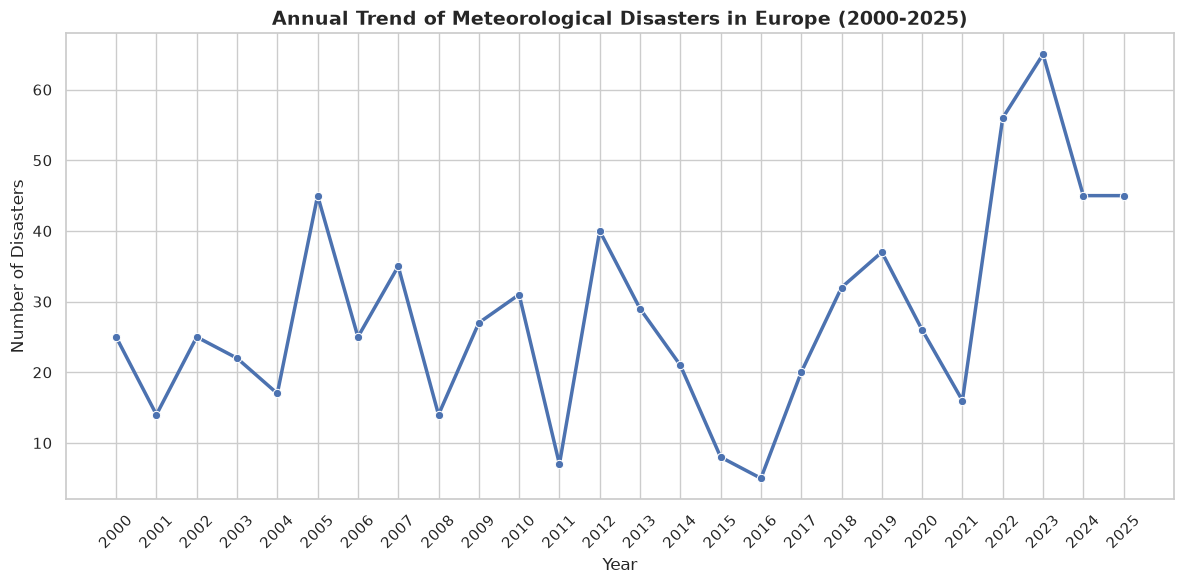

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the aesthetic style of the plot
sns.set_theme(style="whitegrid")

# Create the line plot
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=disasters_per_year,
    x='Start Year',
    y='Climate Count',
    marker='o',
    color='b',
    linewidth=2.5
)

# Add titles and labels
plt.title('Annual Trend of Meteorological Disasters in Europe (2000-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Disasters', fontsize=12)
plt.xticks(disasters_per_year['Start Year'], rotation=45)

# Show the plot
plt.tight_layout()
plt.show()

In [10]:
# Filter the dataset for only 'Heat wave' disasters
df_heatwaves = df_met_eu[df_met_eu['Disaster Subtype'] == 'Heat wave']

# Display the first few rows of the filtered dataset
display(df_heatwaves.head())
print(f"Total heat waves found: {len(df_heatwaves)}")

display(df_heatwaves.info())

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
15,2022-0465-LIE,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,GLIDE:HT-2022-000399,NaN,LIE,...,NaN,NaN,NaN,NaN,NaN,90.902697,NaN,NaN,2026-08-11,2026-08-11
106,2025-0462-BGR,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,NaN,NaN,BGR,...,NaN,NaN,NaN,NaN,NaN,100.000000,NaN,NaN,2026-08-05,2026-08-28
107,2025-0462-ITA,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,NaN,NaN,ITA,...,NaN,NaN,NaN,NaN,NaN,100.000000,NaN,NaN,2025-07-04,2026-08-28
108,2025-0462-MKD,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,NaN,NaN,MKD,...,NaN,NaN,NaN,NaN,NaN,100.000000,NaN,NaN,2026-08-05,2026-08-28
109,2025-0462-SVK,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,NaN,NaN,SVK,...,NaN,NaN,NaN,NaN,NaN,100.000000,NaN,NaN,2026-08-05,2026-08-28


Total heat waves found: 206
<class 'pandas.DataFrame'>
Index: 206 entries, 15 to 10706
Data columns (total 47 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   DisNo.                                     206 non-null    str    
 1   Historic                                   206 non-null    str    
 2   Classification Key                         206 non-null    str    
 3   Disaster Group                             206 non-null    str    
 4   Disaster Subgroup                          206 non-null    str    
 5   Disaster Type                              206 non-null    str    
 6   Disaster Subtype                           206 non-null    str    
 7   External IDs                               44 non-null     str    
 8   Event Name                                 0 non-null      str    
 9   ISO                                        206 non-null    str    
 10  Country    

None

In [18]:
df_heatwaves["DisNo."].dropna().unique()

<StringArray>
['2022-0465-LIE', '2025-0462-BGR', '2025-0462-ITA', '2025-0462-MKD',
 '2025-0462-SVK', '2025-0462-AUT', '2025-0462-IRL', '2025-0462-CHE',
 '2025-0462-DNK', '2025-0462-GBR',
 ...
 '2007-0235-ROU', '2007-0235-SVK', '2013-0549-GBR', '2019-0296-FRA',
 '2018-0235-BEL', '2018-0235-DEU', '2018-0235-ESP', '2018-0235-NLD',
 '2019-0296-ESP', '2019-0366-BEL']
Length: 206, dtype: str

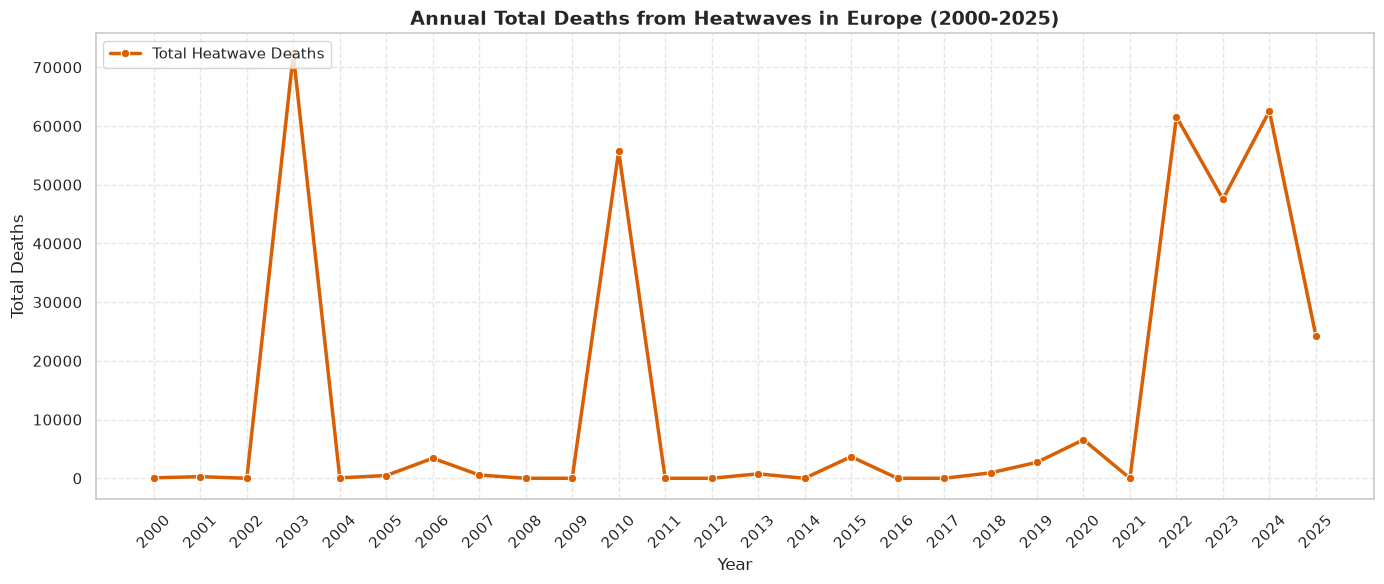

In [11]:
# Plot total number of deaths per year for due to heat waves

# 1. Group by year and sum up total deaths from European heatwaves
deaths_by_year = df_heatwaves.groupby('Start Year')['Total Deaths'].sum().reset_index()

# 2. Reindex with a complete timeline (2000-2025) filling missing years with 0
full_timeline = pd.DataFrame({'Start Year': range(2000, 2026)})
deaths_timeline = pd.merge(full_timeline, deaths_by_year, on='Start Year', how='left').fillna(0)

# 3. Create the line plot
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")

sns.lineplot(
    data=deaths_timeline,
    x='Start Year',
    y='Total Deaths',
    marker='o',
    color='#d95f02',
    linewidth=2.5,
    label='Total Heatwave Deaths'
)

plt.title('Annual Total Deaths from Heatwaves in Europe (2000-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Deaths', fontsize=12)
plt.xticks(deaths_timeline['Start Year'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [12]:
# Calculate heatwave counts per country
country_heatwave_counts = df_heatwaves.groupby('Country').size().reset_index(name='Heatwave Count')
country_heatwave_counts = country_heatwave_counts.sort_values(by='Heatwave Count', ascending=False).reset_index(drop=True)

# Display the table
display(country_heatwave_counts)

,Country,Heatwave Count
0,Belgium,12
1,France,11
2,United Kingdom of Great Britain and Northern I...,10
3,Italy,9
4,Germany,9
5,Romania,9
6,Netherlands (Kingdom of the),9
7,Spain,9
8,Portugal,8
9,Austria,7


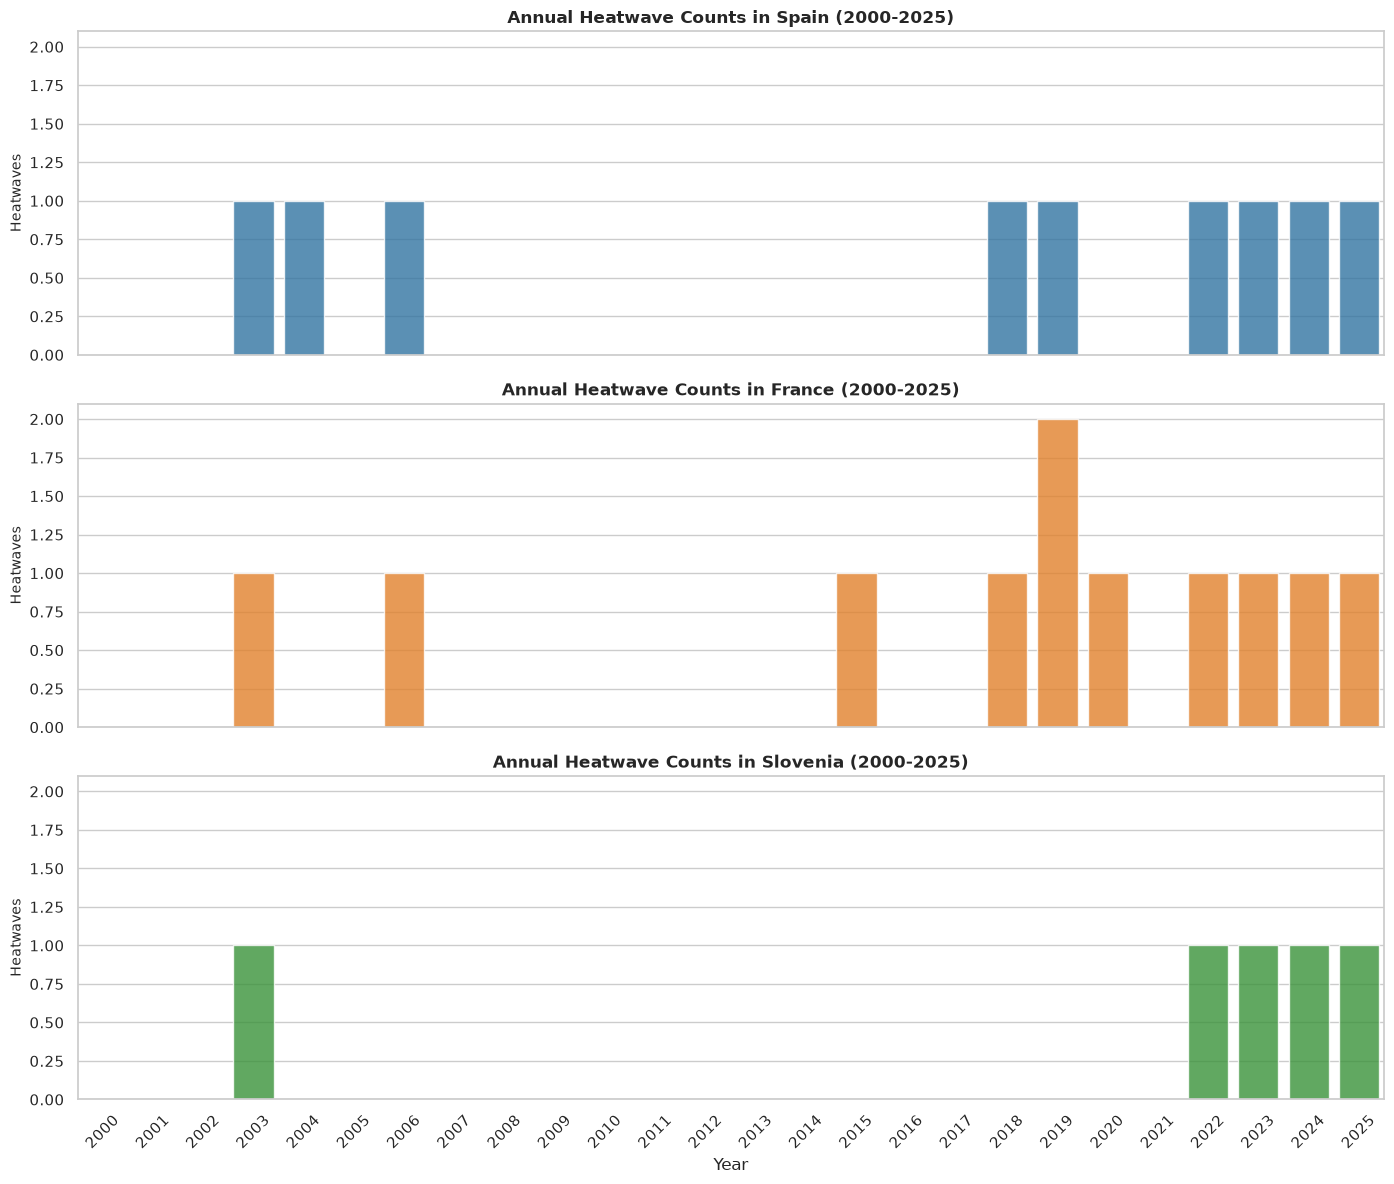

In [13]:
# Plot heatwaves for 2 countries

# 1. Define target countries
target_countries = ['Spain', 'France', 'Slovenia']

# 2. Filter heatwave data for these countries and count annual occurrences
df_target_hw = df_heatwaves[df_heatwaves['Country'].isin(target_countries)]
counts_by_country_year = df_target_hw.groupby(['Country', 'Start Year']).size().reset_index(name='Heatwave Count')

# 3. Build a complete year grid (2000-2025) for each country so missing years show as 0
years_grid = pd.MultiIndex.from_product(
    [target_countries, range(2000, 2026)],
    names=['Country', 'Start Year']
).to_frame().reset_index(drop=True)

# Merge grid with counts and fill NaNs with 0
country_hw_complete = pd.merge(years_grid, counts_by_country_year, on=['Country', 'Start Year'], how='left').fillna(0)
country_hw_complete['Heatwave Count'] = country_hw_complete['Heatwave Count'].astype(int)

# 4. Create the subplots
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True, sharey=True)
sns.set_theme(style="whitegrid")

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
short_names = {'Spain': 'Spain', 'France': 'France', 'Slovenia': 'Slovenia'}

for i, country in enumerate(target_countries):
    country_data = country_hw_complete[country_hw_complete['Country'] == country]
    sns.barplot(
        ax=axes[i],
        data=country_data,
        x='Start Year',
        y='Heatwave Count',
        color=colors[i],
        alpha=0.8
    )
    axes[i].set_title(f'Annual Heatwave Counts in {short_names[country]} (2000-2025)', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Heatwaves', fontsize=10)
    axes[i].set_xlabel('')

plt.xlabel('Year', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

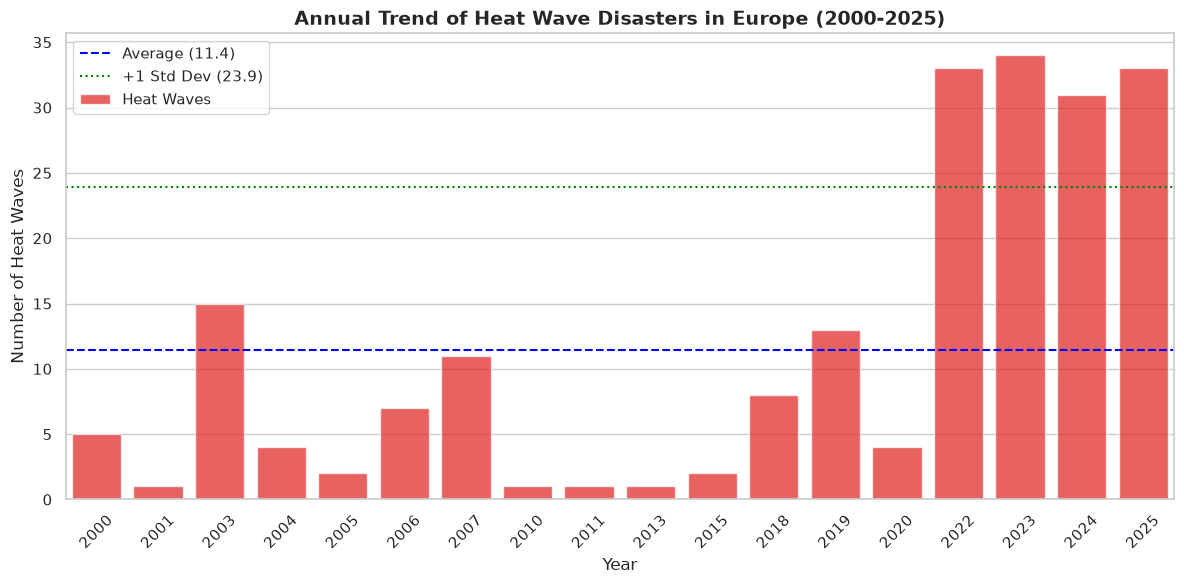

In [14]:
# Calculate the number of heat waves per year
heatwaves_per_year = df_heatwaves.groupby('Start Year').size().reset_index(name='Heatwave Count')

# Calculate mean and standard deviation
mean_val = heatwaves_per_year['Heatwave Count'].mean()
std_val = heatwaves_per_year['Heatwave Count'].std()

# Create the bar plot using Seaborn
plt.figure(figsize=(12, 6))
sns.barplot(
    data=heatwaves_per_year,
    x='Start Year',
    y='Heatwave Count',
    color='red',
    alpha=0.7,
    label='Heat Waves'
)

# Add horizontal lines for Average and Standard Deviation thresholds
plt.axhline(mean_val, color='blue', linestyle='--', linewidth=1.5, label=f'Average ({mean_val:.1f})')
plt.axhline(mean_val + std_val, color='green', linestyle=':', linewidth=1.5, label=f'+1 Std Dev ({mean_val + std_val:.1f})')

# Set labels and title
plt.title('Annual Trend of Heat Wave Disasters in Europe (2000-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Heat Waves', fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc='upper left')

# Show the visualization
plt.tight_layout()
plt.show()

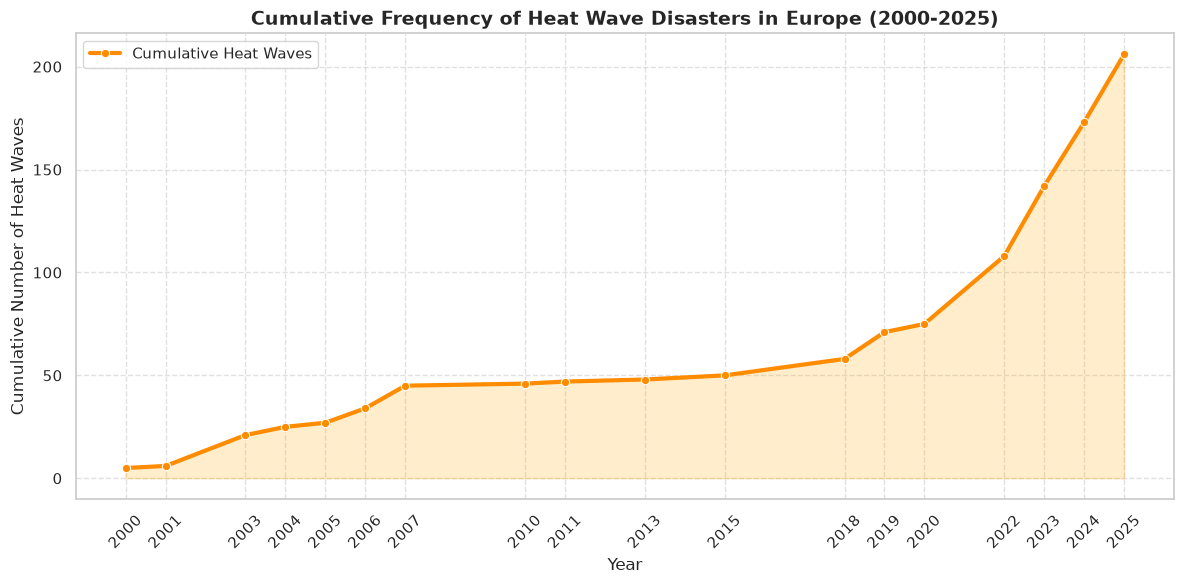

In [15]:
# Sort chronologically and compute cumulative sum of heat wave occurrences
heatwaves_cumulative = heatwaves_per_year.sort_values('Start Year').copy()
heatwaves_cumulative['Cumulative Count'] = heatwaves_cumulative['Heatwave Count'].cumsum()

# Plot the cumulative count
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=heatwaves_cumulative,
    x='Start Year',
    y='Cumulative Count',
    marker='o',
    color='darkorange',
    linewidth=3,
    label='Cumulative Heat Waves'
)

# Fill under the line to emphasize acceleration
plt.fill_between(
    heatwaves_cumulative['Start Year'],
    heatwaves_cumulative['Cumulative Count'],
    color='orange',
    alpha=0.2
)

# Customize plot
plt.title('Cumulative Frequency of Heat Wave Disasters in Europe (2000-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Cumulative Number of Heat Waves', fontsize=12)
plt.xticks(heatwaves_cumulative['Start Year'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

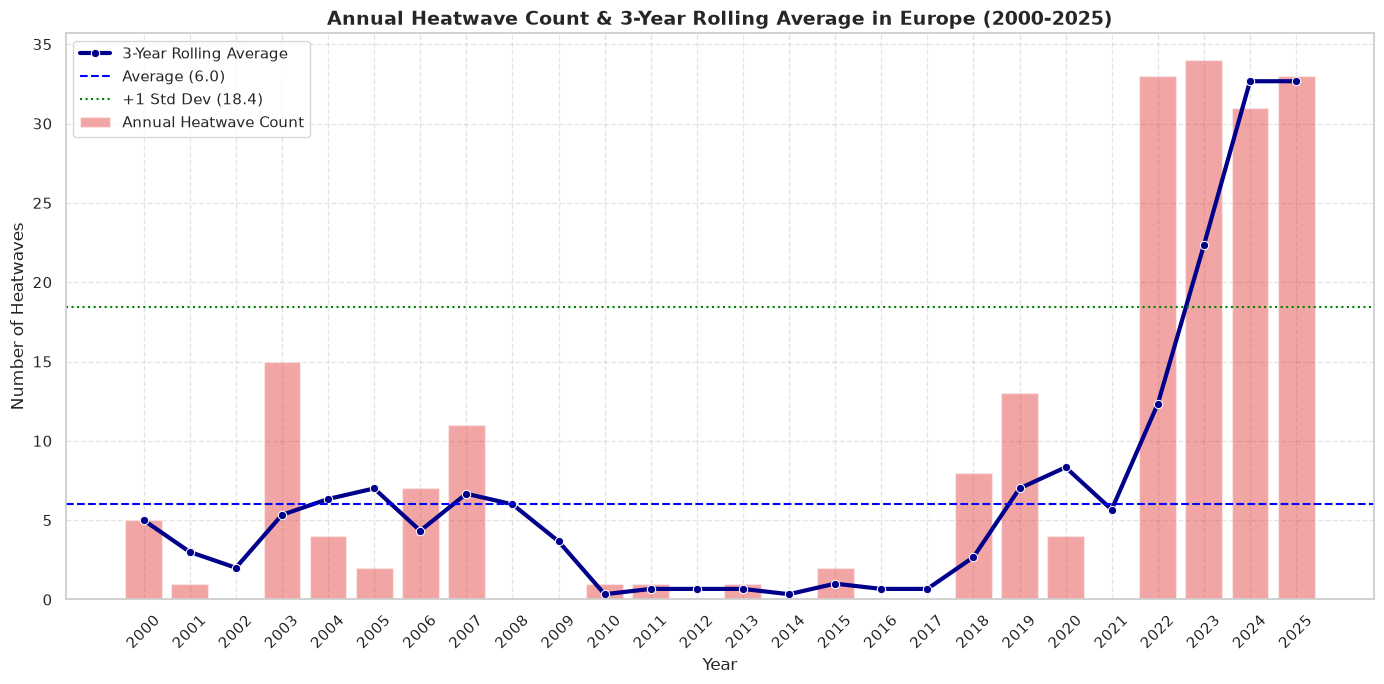

In [16]:
# Add rolling average plus mean

# 1. Create a complete timeline of years from 2000 to 2025
all_years = pd.DataFrame({'Start Year': range(2000, 2026)})

# 2. Merge with existing heatwave counts and fill missing years with 0
heatwaves_complete = pd.merge(all_years, heatwaves_per_year, on='Start Year', how='left').fillna(0)

# 3. Compute the 3-year rolling average (min_periods=1 to handle the boundaries gracefully)
heatwaves_complete['Rolling 3-Year Avg'] = heatwaves_complete['Heatwave Count'].rolling(window=3, min_periods=1).mean()

# Calculate mean and standard deviation
mean_val = heatwaves_per_year['Heatwave Count'].median()
std_val = heatwaves_per_year['Heatwave Count'].std()

# 4. Plot the results
plt.figure(figsize=(14, 7))

# Bar plot for actual annual counts
sns.barplot(
    data=heatwaves_complete,
    x='Start Year',
    y='Heatwave Count',
    color='red',
    alpha=0.4,
    label='Annual Heatwave Count'
)

# Line plot for the rolling average trend line
sns.lineplot(
    data=heatwaves_complete,
    x=range(len(heatwaves_complete)),  # Use numerical index alignment with bar chart positions
    y='Rolling 3-Year Avg',
    color='darkblue',
    linewidth=3,
    marker='o',
    label='3-Year Rolling Average'
)

# Add horizontal lines for Average and Standard Deviation thresholds
plt.axhline(mean_val, color='blue', linestyle='--', linewidth=1.5, label=f'Average ({mean_val:.1f})')
plt.axhline(mean_val + std_val, color='green', linestyle=':', linewidth=1.5, label=f'+1 Std Dev ({mean_val + std_val:.1f})')

# Visual enhancements
plt.title('Annual Heatwave Count & 3-Year Rolling Average in Europe (2000-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Heatwaves', fontsize=12)
plt.xticks(ticks=range(len(heatwaves_complete)), labels=heatwaves_complete['Start Year'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [17]:
# Statistical analysis

import numpy as np
import statsmodels.api as sm

# 1. Prepare variables for regression (X: Year, y: Heatwave Count)
X = heatwaves_complete['Start Year']
y = heatwaves_complete['Heatwave Count']

# Add constant for intercept
X_with_constant = sm.add_constant(X)

# 2. Fit Ordinary Least Squares (OLS) model
model = sm.OLS(y, X_with_constant).fit()

# Extract statistical details
slope = model.params['Start Year']
intercept = model.params['const']
p_value = model.pvalues['Start Year']
r_squared = model.rsquared

# Print summary details
print(model.summary())
print(f"\n--- Regression Trend Analysis Summary ---")
print(f"Slope (Rate of change per year): {slope:.3f} heatwaves/year")
print(f"Intercept: {intercept:.3f}")
print(f"P-value: {p_value:.5f} (Statistically significant if < 0.05)")
print(f"R-squared: {r_squared:.3f}")

ModuleNotFoundError: No module named 'statsmodels'

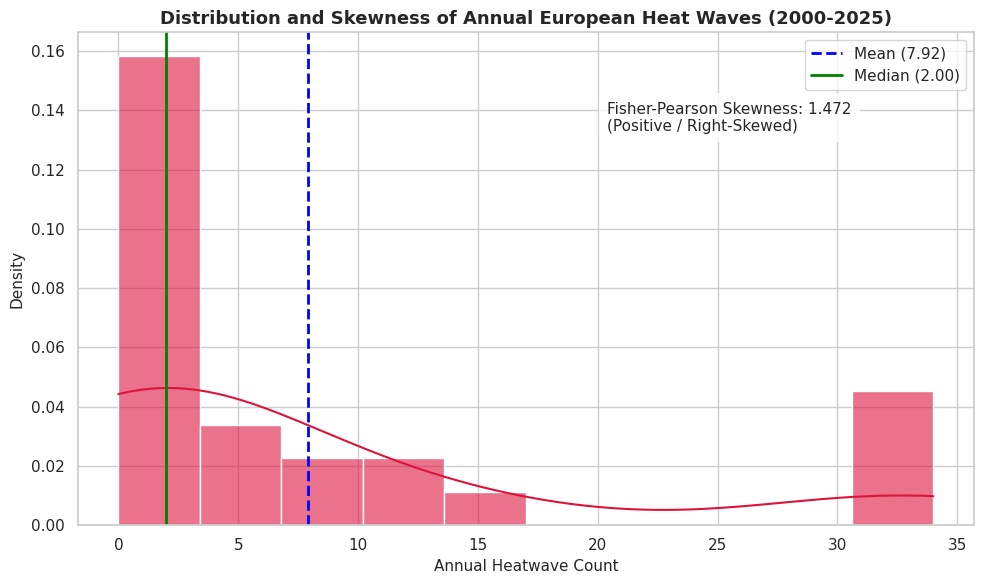

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

# Calculate skewness metric on the complete annual heatwave counts (including zero years)
counts = heatwaves_complete['Heatwave Count']
skew_coef = skew(counts)
mean_val = counts.mean()
median_val = counts.median()

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Density and Histogram distribution plot
sns.histplot(counts, kde=True, color='crimson', bins=10, stat="density", alpha=0.6)

# Visual lines for central tendency indicating skewness
plt.axvline(mean_val, color='blue', linestyle='--', linewidth=2, label=f'Mean ({mean_val:.2f})')
plt.axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median ({median_val:.2f})')

# Add details and title
plt.title('Distribution and Skewness of Annual European Heat Waves (2000-2025)', fontsize=13, fontweight='bold')
plt.xlabel('Annual Heatwave Count', fontsize=11)
plt.ylabel('Density', fontsize=11)

# Annotate the calculated skewness
plt.text(
    x=counts.max() * 0.6,
    y=plt.gca().get_ylim()[1] * 0.8,
    s=f'Fisher-Pearson Skewness: {skew_coef:.3f}\n(Positive / Right-Skewed)',
    fontsize=11,
    bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5')
)

plt.legend()
plt.tight_layout()
plt.show()

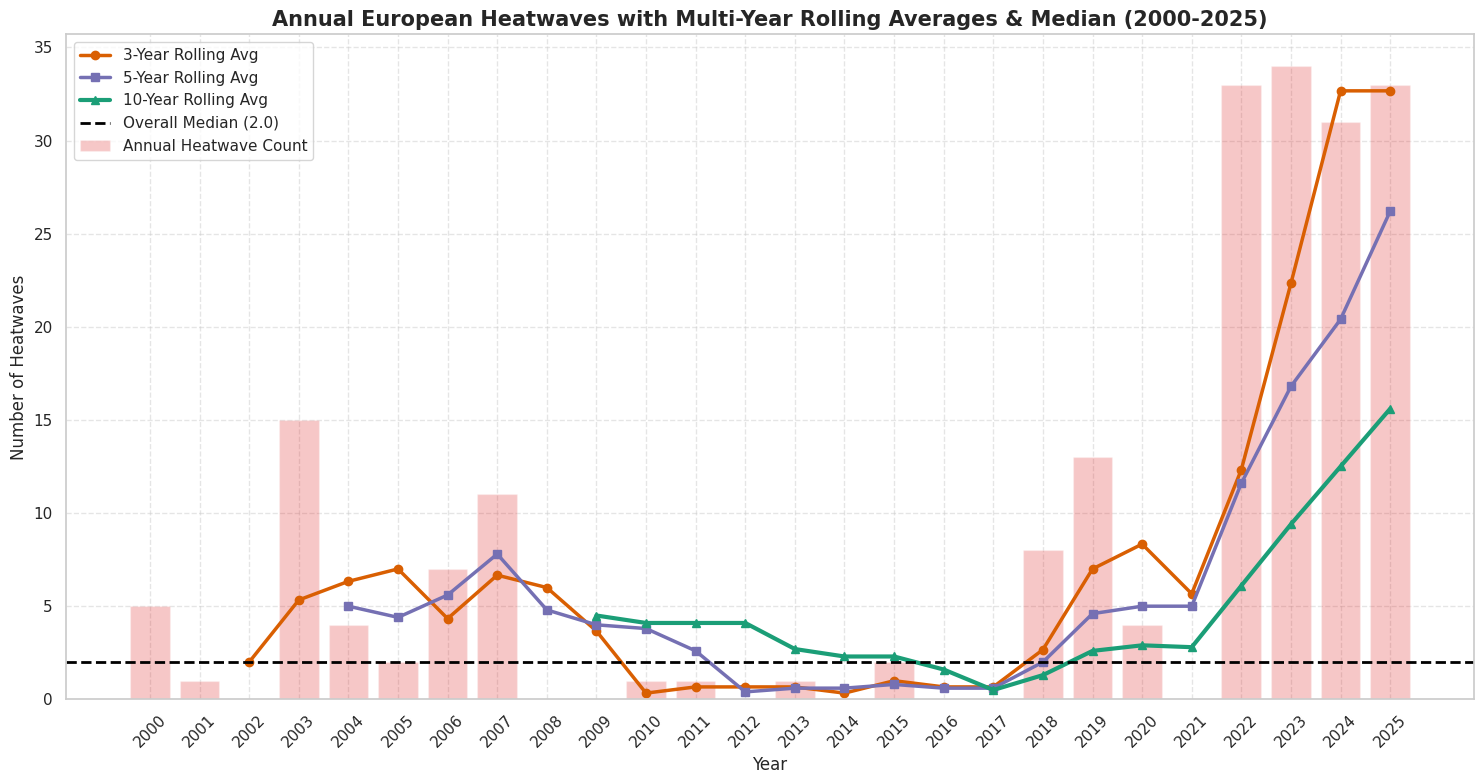

In [ ]:
# Plot 3, 5  and 10-year rolling average plus median

# 1. Use the completed annual heatwave dataset
df_hw_roll = heatwaves_complete.copy()

# 2. Compute rolling averages for 3, 5, and 10 years (min_periods=1 to handle boundaries)
df_hw_roll['3-Year Rolling Avg'] = df_hw_roll['Heatwave Count'].rolling(window=3, min_periods=3).mean()
df_hw_roll['5-Year Rolling Avg'] = df_hw_roll['Heatwave Count'].rolling(window=5, min_periods=5).mean()
df_hw_roll['10-Year Rolling Avg'] = df_hw_roll['Heatwave Count'].rolling(window=10, min_periods=10).mean()

# 3. Calculate overall median for the whole period
overall_median = df_hw_roll['Heatwave Count'].median()

# 4. Plotting
plt.figure(figsize=(15, 8))
sns.set_theme(style="whitegrid")

# Bar chart for original annual heatwave counts
sns.barplot(
    data=df_hw_roll,
    x='Start Year',
    y='Heatwave Count',
    color='red',
    alpha=0.25,
    label='Annual Heatwave Count'
)

# Aligning line plots with bar positions using integer indices
x_indices = range(len(df_hw_roll))

# Plot the rolling averages
plt.plot(x_indices, df_hw_roll['3-Year Rolling Avg'], label='3-Year Rolling Avg', color='#d95f02', linewidth=2.5, marker='o')
plt.plot(x_indices, df_hw_roll['5-Year Rolling Avg'], label='5-Year Rolling Avg', color='#7570b3', linewidth=2.5, marker='s')
plt.plot(x_indices, df_hw_roll['10-Year Rolling Avg'], label='10-Year Rolling Avg', color='#1b9e77', linewidth=3.0, marker='^')

# Plot the baseline median line
plt.axhline(overall_median, color='black', linestyle='--', linewidth=2, label=f'Overall Median ({overall_median:.1f})')

# Aesthetics
plt.title('Annual European Heatwaves with Multi-Year Rolling Averages & Median (2000-2025)', fontsize=15, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Heatwaves', fontsize=12)
plt.xticks(ticks=x_indices, labels=df_hw_roll['Start Year'], rotation=45)
plt.legend(loc='upper left', frameon=True, fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Create table

# Select the columns representing year and count, then display the table
heatwave_table = heatwaves_complete[['Start Year', 'Heatwave Count']].copy()
heatwave_table.columns = ['Year', 'Heatwave Count']

# Convert counts to integer for cleaner display
heatwave_table['Heatwave Count'] = heatwave_table['Heatwave Count'].astype(int)

display(heatwave_table)

,Year,Heatwave Count
0,2000,5
1,2001,1
2,2002,0
3,2003,15
4,2004,4
5,2005,2
6,2006,7
7,2007,11
8,2008,0
9,2009,0


In [ ]:
# Save table
import os

# Define the target directory and file path
target_dir = '/content/drive/MyDrive/Open Data/EMDAT/'
os.makedirs(target_dir, exist_ok=True)

file_path_csv = os.path.join(target_dir, 'EMDAT_Europe_Heatwave_Counts_2000_2025.csv')

# Save the heatwave_table to CSV
heatwave_table.to_csv(file_path_csv, index=False)
print(f"Successfully saved the table to: {file_path_csv}")

Successfully saved the table to: /content/drive/MyDrive/Open Data/EMDAT/EMDAT_Europe_Heatwave_Counts_2000_2025.csv


In [ ]:
# Create new table with rolling averages

# 1. Create a copy of the completed dataset
heatwave_table_detailed = heatwaves_complete[['Start Year', 'Heatwave Count']].copy()
heatwave_table_detailed.columns = ['Year', 'Heatwave Count']

# Ensure count is integer
heatwave_table_detailed['Heatwave Count'] = heatwave_table_detailed['Heatwave Count'].astype(int)

# 2. Add rolling averages (matching the logic in your multi-year trend plot)
heatwave_table_detailed['3-Year Rolling Avg'] = heatwave_table_detailed['Heatwave Count'].rolling(window=3, min_periods=3).mean()
heatwave_table_detailed['5-Year Rolling Avg'] = heatwave_table_detailed['Heatwave Count'].rolling(window=5, min_periods=5).mean()
heatwave_table_detailed['10-Year Rolling Avg'] = heatwave_table_detailed['Heatwave Count'].rolling(window=10, min_periods=10).mean()

# 3. Add the overall median value as a constant reference column
overall_median_val = heatwave_table_detailed['Heatwave Count'].median()
heatwave_table_detailed['Overall Median'] = overall_median_val

# Display the detailed table
display(heatwave_table_detailed)

# 4. Save the detailed table back to Google Drive
target_dir = '/content/drive/MyDrive/Open Data/EMDAT/'
os.makedirs(target_dir, exist_ok=True)
file_path_detailed_csv = os.path.join(target_dir, 'EMDAT_Europe_Heatwave_Detailed_Counts_2000_2025.csv')
heatwave_table_detailed.to_csv(file_path_detailed_csv, index=False)
print(f"\nSuccessfully saved the detailed table to: {file_path_detailed_csv}")

,Year,Heatwave Count,3-Year Rolling Avg,5-Year Rolling Avg,10-Year Rolling Avg,Overall Median
0,2000,5,NaN,NaN,NaN,2.0
1,2001,1,NaN,NaN,NaN,2.0
2,2002,0,2.000000,NaN,NaN,2.0
3,2003,15,5.333333,NaN,NaN,2.0
4,2004,4,6.333333,5.0,NaN,2.0
5,2005,2,7.000000,4.4,NaN,2.0
6,2006,7,4.333333,5.6,NaN,2.0
7,2007,11,6.666667,7.8,NaN,2.0
8,2008,0,6.000000,4.8,NaN,2.0
9,2009,0,3.666667,4.0,4.5,2.0



Successfully saved the detailed table to: /content/drive/MyDrive/Open Data/EMDAT/EMDAT_Europe_Heatwave_Detailed_Counts_2000_2025.csv


In [ ]:
# Let's look at storms now

# Filter the dataset for only 'Heat wave' disasters
df_storm = df_met_eu[df_met_eu['Disaster Type'] == 'Storm']

# Display the first few rows of the filtered dataset
display(df_storm.head())
print(f"Total storms found: {len(df_storm)}")

storms_per_year = df_storm.groupby('Start Year').size().reset_index(name='Sort Count')

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
66,2000-0576-RUS,No,nat-met-sto-tro,Natural,Meteorological,Storm,Tropical cyclone,NaN,Typhoon 'Saomai' (Osang),RUS,...,NaN,NaN,NaN,50.0,93.0,53.487737,"[{""adm1_code"":2516,""adm1_name"":""Khabarovskiy K...","[{""gid_1"":""RUS.28_1"",""migration_date"":""2025-12...",2007-04-18,2026-08-20
71,2000-0714-DEU,No,nat-met-sto-sev,Natural,Meteorological,Storm,Severe weather,HANZE:20231|HANZE:21263,Storm 'Oratia' (Tora),DEU,...,NaN,NaN,NaN,NaN,NaN,53.487737,NaN,NaN,2026-08-19,2026-08-19
72,2000-0714-FRA,No,nat-met-sto-sev,Natural,Meteorological,Storm,Severe weather,HANZE:20231|HANZE:21263,Storm 'Oratia' (Tora),FRA,...,NaN,NaN,NaN,NaN,NaN,53.487737,NaN,NaN,2026-08-19,2026-08-19
73,2000-0714-GBR,No,nat-met-sto-sev,Natural,Meteorological,Storm,Severe weather,HANZE:20231|HANZE:21263,Storm 'Oratia' (Tora),GBR,...,NaN,1100000.0,2056546.0,1500000.0,2804381.0,53.487737,"[{""adm2_code"":40107,""adm2_name"":""East Sussex""}...","[{""gid_2"":""GBR.1.105_1"",""migration_date"":""2025...",2008-04-08,2026-08-19
115,2002-0557-RUS,No,nat-met-sto-tro,Natural,Meteorological,Storm,Tropical cyclone,NaN,Typhoon 'Rusa',RUS,...,NaN,NaN,NaN,NaN,NaN,55.871696,NaN,NaN,2026-08-26,2026-08-26


Total storms found: 376


In [ ]:
# 1. Create a complete timeline of years from 2000 to 2025
all_years = pd.DataFrame({'Start Year': range(2000, 2026)})

# 2. Merge with existing heatwave counts and fill missing years with 0
storm_complete = pd.merge(all_years, storms_per_year, on='Start Year', how='left').fillna(0)

In [ ]:
storm_complete

,Start Year,Sort Count
0,2000,14
1,2001,5
2,2002,22
3,2003,6
4,2004,13
5,2005,24
6,2006,8
7,2007,23
8,2008,11
9,2009,10


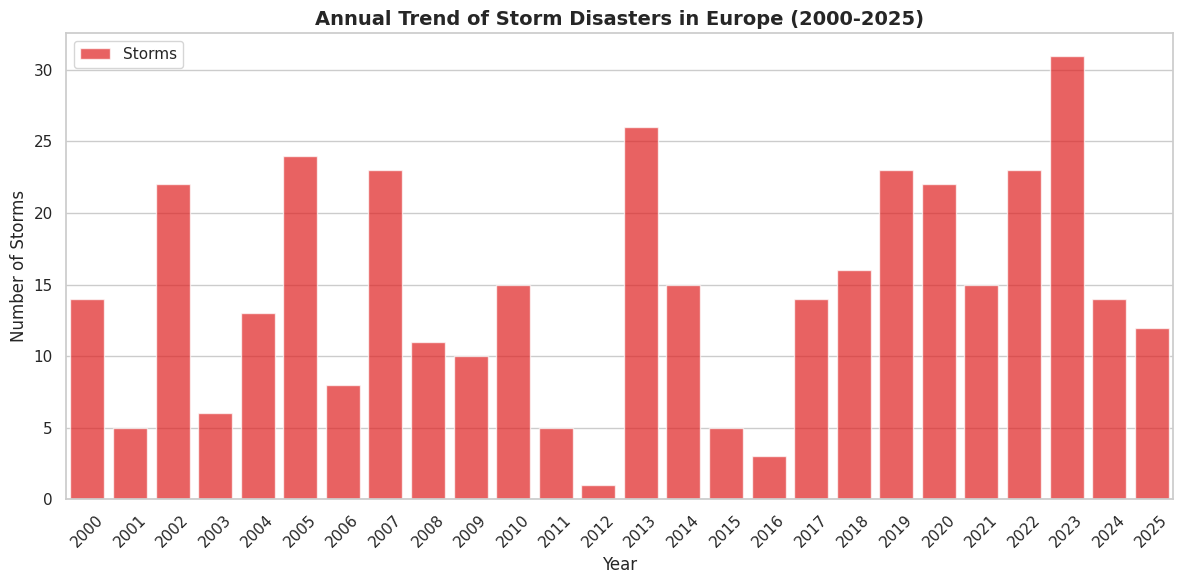

In [ ]:
# Plot storms per year

# Create the bar plot using Seaborn
plt.figure(figsize=(12, 6))
sns.barplot(
    data=storm_complete,
    x='Start Year',
    y='Sort Count',
    color='red',
    alpha=0.7,
    label='Storms'
)

# Set labels and title
plt.title('Annual Trend of Storm Disasters in Europe (2000-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Storms', fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc='upper left')

# Show the visualization
plt.tight_layout()
plt.show()